#**PROJECT TITLE: BUSINESS PERFORMANCE & PROFITABILITY ANALYSIS: SALES, REVENUE & OPERATIONAL INSIGHT**


##**Project Goal**

*  Exploratory Data Analysis (EDA) of business sales data
*  Sales, revenue, and profitability analysis
*  Business and operational performance analysis
*  Data visualization using matplotlib and seaborn
*  Business insight generation to support data-driven decision-making


###**Libraries Used**
**Pandas** : Used for data loading, cleaning, manipulation, and analysis.

**NumPy** : Used for numerical calculations and working with numerical data.

**Matplotlib** : Used to create basic data visualizations and charts.

**Seaborn** : Used to create statistical and advanced visualizations.

**Plotly**: Used to create interactive visualizations.

In [ ]:
!pip install plotly

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
import warnings
warnings.filterwarnings("ignore")


In [ ]:
df=pd.read_csv("/content/raw_sales_data.csv")

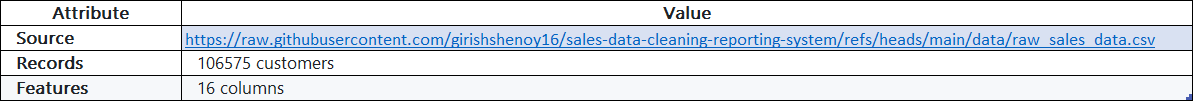

In [ ]:
df

,Order ID,Customer ID,Customer Name,Order Date,Region,State,Product Category,Product Name,Quantity Sold,Unit Price,Sales Amount,Discount %,Profit Amount,Sales Representative,Payment Method,Delivery Status
0,ORD-2025-140269,CUST-19529,Customer 19529,21-09-2025,South,TN,Furniture,Sofa,9.0,609.80,4390.56,0.2,737.66,Charlie Brown,Credit Card,Pending
1,ORD-2025-149795,CUST-17326,Customer 17326,18-01-2025,South,TX,Furniture,Table,12.0,207.94,2245.75,0.1,443.84,Bob Jones,Debit Card,Delivered
2,ORD-2025-126346,CUST-11851,Customer 11851,30-05-2025,South,GA,Furnitures,Desk,10.0,367.42,2939.36,0.2,-310.26,Bob Jones,Debit Card,Pending
3,ORD-2025-175118,CUST-11165,Customer 11165,03-03-2025,East,NJ,Technology,Laptop,8.0,1200.23,9601.84,0.0,2375.75,Bob Jones,Credit Card,Delivered
4,ORD-2025-188926,CUST-18986,Customer 18986,22-01-2025,South,GA,Furniture,Table,15.0,198.49,2679.62,0.1,351.69,Frank Thomas,PayPal,Delivered
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106570,ORD-2025-116003,CUST-17916,Customer 17916,06-04-2025,East,MA,Furniture,Table,7.0,205.92,1297.30,0.1,237.38,Alice Smith,PayPal,Shipped
106571,ORD-2025-169170,CUST-11953,Customer 11953,12-03-2025,West,WA,Technology,Keyboard,3.0,52.06,140.56,0.1,32.39,Bob Jones,Debit Card,Delivered
106572,ORD-2025-165435,CUST-19841,Customer 19841,02-02-2025,West,CO,Office Supplies,Calculator,13.0,23.71,308.23,0.0,135.15,Frank Thomas,Debit Card,Delivered
106573,ORD-2025-128286,CUST-16760,Customer 16760,30-03-2026,North,IL,Office Supplies,Binder,9.0,8.02,72.18,0.0,30.26,Frank Thomas,PayPal,Cancelled


## **Understanding the Dataset Structure**

In [ ]:
df.shape  # 106575 rows and 16 columns

(106575, 16)

In [ ]:
df.columns

Index(['Order ID', 'Customer ID', 'Customer Name', 'Order Date', 'Region',
       'State', 'Product Category', 'Product Name', 'Quantity Sold',
       'Unit Price', 'Sales Amount', 'Discount %', 'Profit Amount',
       'Sales Representative', 'Payment Method', 'Delivery Status'],
      dtype='object')

In [ ]:
df.dtypes

,0
Order ID,object
Customer ID,object
Customer Name,object
Order Date,object
Region,object
State,object
Product Category,object
Product Name,object
Quantity Sold,float64
Unit Price,float64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 106575 entries, 0 to 106574
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Order ID              106575 non-null  object 
 1   Customer ID           106575 non-null  object 
 2   Customer Name         105021 non-null  object 
 3   Order Date            106575 non-null  object 
 4   Region                106575 non-null  object 
 5   State                 106575 non-null  object 
 6   Product Category      106575 non-null  object 
 7   Product Name          106575 non-null  object 
 8   Quantity Sold         104989 non-null  float64
 9   Unit Price            106575 non-null  float64
 10  Sales Amount          106575 non-null  float64
 11  Discount %            104466 non-null  float64
 12  Profit Amount         106575 non-null  float64
 13  Sales Representative  106575 non-null  object 
 14  Payment Method        104355 non-null  object 
 15  

## **Checking Missing Values**

In [ ]:
df.isnull().sum()

,0
Order ID,0
Customer ID,0
Customer Name,1554
Order Date,0
Region,0
State,0
Product Category,0
Product Name,0
Quantity Sold,1586
Unit Price,0


In [ ]:
df.isnull().sum()[df.isnull().sum()>0]

,0
Customer Name,1554
Quantity Sold,1586
Discount %,2109
Payment Method,2220


## **Checking Duplicate Records**

In [ ]:
df.duplicated().sum()

np.int64(1575)

In [ ]:
df[df.duplicated()]

,Order ID,Customer ID,Customer Name,Order Date,Region,State,Product Category,Product Name,Quantity Sold,Unit Price,Sales Amount,Discount %,Profit Amount,Sales Representative,Payment Method,Delivery Status
6697,ORD-2025-157513,CUST-17733,Customer 17733,14-02-2025,South,VA,Furniture,Desk,6.0,346.77,1664.50,0.20,177.85,David Miller,Credit Card,Pending
6829,ORD-2025-145318,CUST-13581,Customer 13581,02-04-2026,East,MA,Technology,Laptop,13.0,1089.91,13460.39,0.05,2747.39,David Miller,Bank Transfer,Delivered
6901,ORD-2025-103492,CUST-11168,Customer 11168,27-02-2026,west,AZ,Furniture,Bookshelf,13.0,197.38,2309.35,0.10,371.32,Emma Wilson,Debit Card,Shipped
7542,ORD-2025-116447,CUST-12050,Customer 12050,07-04-2026,West,CO,Office Supplies,Pens Set,11.0,5.44,59.84,0.00,22.00,Alice Smith,Credit Card,Cancelled
7709,ORD-2025-145025,CUST-12167,Customer 12167,07-10-2025,NORTH,IN,Technology,Smartphone,NaN,829.87,0.00,0.15,0.00,David Miller,Credit Card,Cancelled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106400,ORD-2025-116283,CUST-11217,Customer 11217,04-10-2025,West,OR,Furniture,Filing Cabinet,5.0,154.48,733.78,0.05,102.85,Emma Wilson,Credit Card,Cancelled
106415,ORD-2025-181132,CUST-14166,Customer 14166,08-09-2025,North,NY,Technology,Laptop,2.0,1139.45,2278.90,0.00,671.49,Bob Jones,PayPal,Pending
106442,ORD-2025-138380,CUST-14423,Customer 14423,03-10-2025,North,IL,Technology,Headphones,10.0,152.35,1523.50,0.00,338.71,Emma Wilson,Bank Transfer,Delivered
106450,ORD-2025-119681,CUST-19516,Customer 19516,17-08-2025,East,NJ,Office Supplies,Calculator,15.0,24.71,333.59,0.10,136.48,David Miller,Credit Card,Cancelled


## **Removing Duplicate Records**

In [ ]:
df=df.drop_duplicates()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 105000 entries, 0 to 106574
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Order ID              105000 non-null  object 
 1   Customer ID           105000 non-null  object 
 2   Customer Name         103471 non-null  object 
 3   Order Date            105000 non-null  object 
 4   Region                105000 non-null  object 
 5   State                 105000 non-null  object 
 6   Product Category      105000 non-null  object 
 7   Product Name          105000 non-null  object 
 8   Quantity Sold         103437 non-null  float64
 9   Unit Price            105000 non-null  float64
 10  Sales Amount          105000 non-null  float64
 11  Discount %            102911 non-null  float64
 12  Profit Amount         105000 non-null  float64
 13  Sales Representative  105000 non-null  object 
 14  Payment Method        102809 non-null  object 
 15  Deliv

After removing 1,575 duplicate records, the dataset contains 105,000 records and 16 columns.

## **Converting Date Data Type**

In [ ]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed",
    dayfirst=True
)

df["Order Date"].dtype

dtype('<M8[ns]')

In [ ]:
df["Order Year"] = df["Order Date"].dt.year

In [ ]:
df["Order Month"] = df["Order Date"].dt.month_name()

In [ ]:
df["Order YearMonth"] = df["Order Date"].dt.to_period("M")

## **Handle Missing Values**

In [ ]:
missing_percentage=df.isnull().mean()*100    #check's what percentage of each column is missing

missing_percentage

,0
Order ID,0.000000
Customer ID,0.000000
Customer Name,1.456190
Order Date,0.000000
Region,0.000000
State,0.000000
Product Category,0.000000
Product Name,0.000000
Quantity Sold,1.488571
Unit Price,0.000000


In [ ]:
missing_percentage[missing_percentage>0]

,0
Customer Name,1.456190
Quantity Sold,1.488571
Discount %,1.989524
Payment Method,2.086667


### **1. Handling Missing Value in Customer Name**

In [ ]:
df["Customer Name"].isnull().sum()

np.int64(1529)

In [ ]:
df["Customer Name"]=df["Customer Name"].fillna("unknown")

In [ ]:
df["Customer Name"].isnull().sum()

np.int64(0)

### **2. Handling Missing Value in Quantity Sold**

In [ ]:
df["Quantity Sold"].isnull().sum()

np.int64(1563)

In [ ]:
df["Calculated Quantity"] = df["Sales Amount"] /(df["Unit Price"] * (1 - df["Discount %"]))


In [ ]:
df[["Quantity Sold", "Calculated Quantity"]].head(10).round()

,Quantity Sold,Calculated Quantity
0,9.0,9.0
1,12.0,12.0
2,10.0,10.0
3,8.0,8.0
4,15.0,15.0
5,12.0,12.0
6,9.0,9.0
7,15.0,15.0
8,15.0,15.0
9,8.0,8.0


In [ ]:
(df["Quantity Sold"].round() == df["Calculated Quantity"].round()).value_counts()

,count
True,97476
False,7524


In [ ]:
df.loc[(df["Quantity Sold"].round(0) != df["Calculated Quantity"].round(0)),
    ["Quantity Sold", "Calculated Quantity"]].head(20).round()

,Quantity Sold,Calculated Quantity
19,9.0,NaN
27,NaN,0.0
29,9.0,4.0
64,NaN,0.0
88,13.0,6.0
94,4.0,6.0
100,13.0,NaN
149,9.0,4.0
157,8.0,16.0
162,13.0,NaN


In [ ]:
difference = abs(df["Quantity Sold"] - df["Calculated Quantity"])

df.loc[
    difference >= 2,
    ["Quantity Sold", "Calculated Quantity"]
].head(20)

,Quantity Sold,Calculated Quantity
29,9.0,4.500000
88,13.0,6.499779
94,4.0,6.000000
149,9.0,4.499991
157,8.0,16.000000
176,11.0,21.999304
183,7.0,14.000026
184,12.0,23.999913
213,13.0,6.500000
219,3.0,6.000048


In [ ]:
negative_records = df[
    (df["Quantity Sold"] < 0) &
    (df["Sales Amount"] < 0)
]

negative_records.head()

,Order ID,Customer ID,Customer Name,Order Date,Region,State,Product Category,Product Name,Quantity Sold,Unit Price,Sales Amount,Discount %,Profit Amount,Sales Representative,Payment Method,Delivery Status,Order Year,Order Month,Order YearMonth,Calculated Quantity
222,ORD-2025-135196,CUST-16108,Customer 16108,2025-09-07,W. Region,WA,Office Supplies,Paper Pack,-5.0,15.78,-67.06,0.15,-25.69,Charlie Brown,Credit Card,Cancelled,2025,September,2025-09,-4.999627
259,ORD-2025-161721,CUST-15332,Customer 15332,2026-01-11,North,IL,Technology,Monitor,-4.0,306.43,-1164.43,0.05,-255.07,Charlie Brown,Bank Transfer,Delivered,2026,January,2026-01,-3.999986
405,ORD-2025-203200,CUST-15282,Customer 15282,2025-04-25,North,NY,Technology,Smartphone,-8.0,752.22,-6017.76,0.00,-1734.60,Frank Thomas,Credit Card,Cancelled,2025,April,2025-04,-8.000000
436,ORD-2025-138325,CUST-14730,Customer 14730,2026-02-26,West,CA,Furniture,Bookshelf,-2.0,172.81,-345.62,0.00,-52.60,Charlie Brown,Debit Card,Shipped,2026,February,2026-02,-2.000000
604,ORD-2025-181538,CUST-12822,Customer 12822,2025-09-26,South,NC,Furniture,Filing Cabinet,-9.0,5921.11,-47960.99,0.10,-5260.46,Charlie Brown,Bank Transfer,Delivered,2025,September,2025-09,-9.000000


In [ ]:
negative_records["Delivery Status"].value_counts()

,count
Delivery Status,
Delivered,271
Shipped,248
Pending,245
Cancelled,235


In [ ]:
df.loc[
    (df["Quantity Sold"] < 0) &
    (df["Delivery Status"] != "Cancelled"),
    ["Order ID", "Quantity Sold", "Sales Amount",
     "Profit Amount", "Delivery Status"]
]

,Order ID,Quantity Sold,Sales Amount,Profit Amount,Delivery Status
259,ORD-2025-161721,-4.0,-1164.43,-255.07,Delivered
436,ORD-2025-138325,-2.0,-345.62,-52.60,Shipped
604,ORD-2025-181538,-9.0,-47960.99,-5260.46,Delivered
677,ORD-2025-172559,-8.0,-1280.88,-223.23,Shipped
814,ORD-2025-164089,-4.0,-629.31,-90.91,Shipped
...,...,...,...,...,...
105104,ORD-2025-112700,-4.0,-789.41,-99.34,Delivered
105264,ORD-2025-171434,-8.0,-1941.04,-381.11,Delivered
105461,ORD-2025-127809,-5.0,-1023.87,-156.40,Delivered
106434,ORD-2025-141043,-4.0,-45.52,-19.32,Shipped


In [ ]:
(
    (df["Quantity Sold"] < 0) &
    (df["Delivery Status"] != "Cancelled")
).sum()

####**Outlier Detection Using IQR Method**

In [ ]:
Q1 = df["Quantity Sold"].quantile(0.25)
Q3 = df["Quantity Sold"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR


print("Q1:",Q1)
print("Q1:",Q3)
print("IQR:",IQR)
print("lower_limit:",lower_limit)
print("upper_limit:",upper_limit)

In [ ]:
outliers = df[
    (df["Quantity Sold"] < lower_limit) |
    (df["Quantity Sold"] > upper_limit)
]


In [ ]:
outliers["Quantity Sold"].describe()

In [ ]:
df.loc[:,"Quantity Sold"] = df["Quantity Sold"].fillna(df["Quantity Sold"].median())

The median was used to fill missing Quantity Sold values instead of the mean because the column contains significant outliers. The median is less affected by extreme values, making it a more reliable value for replacing missing quantities.

In [ ]:
df["Quantity Sold"].isnull().sum()

In [ ]:
df.drop(columns=["Calculated Quantity"], inplace=True)

Calculated Quantity was a temporary column created to validate the existing Quantity Sold values. Since the calculated values did not consistently match the actual values, the column was removed after validation.

### **3. Handling Missing Value in Discount %**

In [ ]:
median=df["Discount %"].median()
median

In [ ]:
df["Discount %"] = df["Discount %"].fillna(median)

In [ ]:
df["Discount %"].isnull().sum()

Discount % has some variation (0%, 10%, 15%, 20%), and the median 10% is a reasonable value to use without being strongly affected by extreme values.

### **4. Handling Missing Value in Payment Method**

In [ ]:
df["Payment Method"].value_counts()

In [ ]:
df["Payment Method"] = df["Payment Method"].fillna("Unknown")

In [ ]:
df["Payment Method"].isnull().sum()

Payment Method, 2.086667% of the values were missing. Since the missing values could not be reliably assigned to a specific payment method, they were replaced with "Unknown" rather than assuming a payment method.

In [ ]:
df.isnull().sum()

##**Checking for Inconsistencies**

In [ ]:
df.columns

###**1.Checking Inconsistencies in Product Category**

In [ ]:
df["Product Category"].value_counts()

In [ ]:
category_mapping = {
    "Furnitures": "Furniture",
    "FURNITURE": "Furniture",
    "furni": "Furniture",
    "TECHNOLOGY": "Technology",
    "Tech": "Technology",
    "techno": "Technology",
    "Off. Supplies": "Office Supplies",
    "OFFICE SUPPLIES": "Office Supplies",
    "Office Supp": "Office Supplies"
}

In [ ]:
df.loc[:,"Product Category"] = df["Product Category"].replace(category_mapping)

In [ ]:
df["Product Category"].value_counts()

###**2.Checking Inconsistencies in State**

In [ ]:
df["State"].value_counts()

###**3.Checking Inconsistencies in Product Name**

In [ ]:
df["Product Name"].value_counts()

###**4.Checking Inconsistencies in Sales Representative**

In [ ]:
df["Sales Representative"].value_counts()

###**5. Checking Inconsistencies in Payment Method**

In [ ]:
df["Payment Method"].value_counts()

###**6. Checking Inconsistencies in Delivery Status**

In [ ]:
df["Delivery Status"].value_counts()

###**7. Checking Inconsistencies in Region**

In [ ]:
df["Region"].value_counts()

In [ ]:
region_mapping =( {
    "NORTH": "North",
    "north": "North",
    "N. Region": "North",

    "SOUTH": "South",
    "south": "South",
    "S. Region": "South",

    "EAST": "East",
    "east": "East",
    "E. Region": "East",

    "WEST": "West",
    "west": "West",
    "W. Region": "West"
})

In [ ]:
df.loc[:,"Region"] = df["Region"].replace(region_mapping)

In [ ]:
df["Region"].value_counts()

## **Checking Inconsistencies in Numerical Columns**

###**8. Checking Inconsistencies in Quantity Sold**

In [ ]:
df["Quantity Sold"].describe()

In [ ]:
(df["Quantity Sold"] < 0).sum()

In [ ]:
df.loc[
    df["Quantity Sold"] < 0,
    ["Quantity Sold", "Unit Price", "Sales Amount", "Profit Amount", "Delivery Status"]
].head(20)

In [ ]:
(df["Quantity Sold"] == 0).sum()

**Check 1: Negative Quantity + Delivery Status**

In [ ]:
df.loc[
    df["Quantity Sold"] < 0,
    "Delivery Status"
].value_counts()

**Check 2: Negative Quantity vs Sales Amount**

In [ ]:
df.loc[
    df["Quantity Sold"] < 0,
    "Sales Amount"
].describe()

**check the contradictory records**

In [ ]:
df.loc[
    (df["Quantity Sold"] < 0) &
    (df["Sales Amount"] > 0),
    ["Quantity Sold", "Unit Price", "Sales Amount", "Profit Amount", "Delivery Status"]
]

**Data Inconsistency Investigation: Working Copy**

In [ ]:
columns_to_keep = ['Quantity Sold', 'Unit Price', 'Sales Amount', 'Profit Amount', 'Delivery Status']
df_cleaned = df[columns_to_keep].copy()

df_cleaned = df_cleaned[df_cleaned['Quantity Sold'] < 0]

df_cleaned.head(20)

In [ ]:
columns_to_keep = ['Quantity Sold', 'Unit Price', 'Sales Amount', 'Profit Amount', 'Delivery Status']
df_cleaned = df[columns_to_keep].copy()

df_cleaned = df_cleaned[~df_cleaned['Delivery Status'].str.contains('Cancelled', case=False)]
df_cleaned['Quantity Sold'] = df_cleaned['Quantity Sold'].abs()

df_cleaned.head(20)

In [ ]:
columns_to_keep = ['Quantity Sold', 'Unit Price', 'Sales Amount', 'Profit Amount', 'Delivery Status']
df_cleaned = df[columns_to_keep].copy()


df_cleaned = df_cleaned[~df_cleaned['Delivery Status'].str.contains('Cancelled', case=False, na=False)]


df_cleaned['Quantity Sold'] = df_cleaned['Quantity Sold'].abs()
df_cleaned['Unit Price'] = df_cleaned['Unit Price'].abs()
df_cleaned['Sales Amount'] = df_cleaned['Sales Amount'].abs()


df_cleaned.head(20)

In [ ]:
df_cleaned['Sales Amount'] = (
    df_cleaned['Quantity Sold'] *
    df_cleaned['Unit Price'] *
    (1 - df['Discount %'])
)


df_cleaned.head(20)

In [ ]:

df_cleaned['Sales Amount'] = df.loc[df_cleaned.index, 'Sales Amount'].abs().round(0)

df_cleaned['Sales Amount'] = df_cleaned['Sales Amount'].astype(int)


print(df_cleaned[['Sales Amount']].head(10))

In [ ]:

df_cleaned['Sales Amount'] = df_cleaned['Sales Amount'].round(0).astype(int)

In [ ]:
df_cleaned['Sales Amount'] = df_cleaned['Sales Amount'].abs().round(0)

In [ ]:
comparison_view = pd.DataFrame({
    'Old Sales Amount (Abs)': df.loc[df_cleaned.index, 'Sales Amount'].abs().round(0).astype(int),
    'Calculated Sales Amount': df_cleaned['Sales Amount']
})

comparison_view.head(10)

In [ ]:
old_sales = df.loc[df_cleaned.index, 'Sales Amount'].abs().round(0)
calc_sales = df_cleaned['Sales Amount']

are_equal = (old_sales == calc_sales)
print(f"Equal: {are_equal.sum()}")
print(f"Not Equal: {(~are_equal).sum()}")

Negative values in Quantity Sold and Unit Price caused inconsistencies in Sales Amount; converting them to positive values and recalculating Sales Amount helped verify and correct the inconsistencies.

In [ ]:
df.loc[df_cleaned.index, 'Quantity Sold'] = df_cleaned['Quantity Sold']
df.loc[df_cleaned.index, 'Unit Price'] = df_cleaned['Unit Price']
df.loc[df_cleaned.index, 'Sales Amount'] = df_cleaned['Sales Amount']

###**9. Checking Inconsistencies in Unit Price**

In [ ]:
df["Unit Price"].describe()

In [ ]:
(df["Unit Price"] < 0).sum()

In [ ]:
df.loc[
    df["Unit Price"] < 0,
    [ "Unit Price","Delivery Status"]
].head(20)

In [ ]:
df.loc[
    (df['Unit Price'] < 0) &
    (df['Delivery Status'].str.strip().str.lower() != 'cancelled'),
    ['Unit Price', 'Delivery Status']
]

which means no negative Unit Price values were found outside Cancelled orders.
You can confirm with:

The negative Unit Price values shown are all associated with Cancelled orders. These should be excluded from your main sales and profit KPIs, while keeping the original values unchanged for cancellation analysis.

###**10. Checking Inconsistencies in Sales Amount**

In [ ]:
(df["Sales Amount"] < 0).sum()

In [ ]:
df.loc[
    df["Sales Amount"] < 0,
    [ "Sales Amount","Delivery Status"]
].head(20)

In [ ]:
df.loc[df['Sales Amount'] < 0, 'Delivery Status'].value_counts()

In [ ]:
df.loc[
    (df['Sales Amount'] < 0) &
    (df['Delivery Status'].str.strip().str.lower() != 'cancelled'),
    ['Sales Amount', 'Delivery Status']
]

The Sales Amount column contains negative values in the records shown, and all are associated with Cancelled orders. These should contribute ₹0 to the main sales KPIs, while the original values remain unchanged for cancellation analysis.

In [ ]:
mask = df['Delivery Status'].str.strip().str.lower() == 'cancelled'
df.loc[mask, 'Sales Amount'] = df.loc[mask, 'Sales Amount'].clip(lower=0)

In [ ]:
df.loc[
    (df['Delivery Status'].str.strip().str.lower() == 'cancelled') &
    (df['Sales Amount'] < 0),
    ['Sales Amount', 'Delivery Status']
]

###**10. Checking Inconsistencies in Profit Amount**

In [ ]:
df["Profit Amount"].describe()

**check negative profits**

In [ ]:
(df["Profit Amount"] < 0).sum()

In [ ]:
(df["Profit Amount"] == 0).sum()

In [ ]:
df.loc[df['Profit Amount'] < 0, 'Delivery Status'].value_counts()

In [ ]:
mask = df['Delivery Status'].str.strip().str.lower() == 'cancelled'

df.loc[mask, 'Profit Amount'] = (
    df.loc[mask, 'Profit Amount'].clip(lower=0)
)

In [ ]:
df.loc[df['Profit Amount'] < 0, 'Delivery Status'].value_counts()

In [ ]:
df['Delivery Status'].value_counts()

Negative profit values were found in Delivered (923), Shipped (911), and Pending (901) orders. These values may represent actual business losses

####**Data Quality Validation**

In [ ]:
df["Discount %"].value_counts().sort_index()

In [ ]:
df["Customer Name"].value_counts().head()

In [ ]:
df["Product Name"].value_counts()

In [ ]:
df["Sales Representative"].value_counts()

In [ ]:
df["Payment Method"].value_counts()

In [ ]:
df["Delivery Status"].value_counts()

##**Overall Business Performance**

**1.What is the total sales/revenue generated by the business?**

In [ ]:
total_sales=df["Sales Amount"].sum().round()

total_sales

The business generated total sales revenue of ₹365,268,912 (approximately ₹36.53 crore) during the period covered by the dataset.

**2.What is the total profit?**

In [ ]:
total_profit=df["Profit Amount"].sum().round()

total_profit

The business generated total sales revenue of ₹365,268,912 (approximately ₹36.53 crore) and a total profit of ₹92,319,868 (approximately ₹9.23 crore). This indicates that the business earned a substantial profit from its recorded sales transactions.

**3.What is the overall profit margin?**

In [ ]:
profit_margin=round((df["Profit Amount"].sum() / df["Sales Amount"].sum()) * 100,2)

profit_margin

The business achieved an overall profit margin of 25.27%, meaning it earned approximately ₹25.27 in profit for every ₹100 of sales revenue.

**4.What is the average sales and profit per transaction?**

In [ ]:
average_sales=round(df["Sales Amount"].mean(), 2)

average_sales

In [ ]:
average_profit=round(df["Profit Amount"].mean(), 2)

average_profit

The business recorded an average sales value of ₹3,478.75 and an average profit of ₹879.24 per transaction. This indicates that each transaction generated approximately ₹879.24 in profit on average.

##**Sales & Revenue Performance**

**5.Which product categories generate the highest sales/revenue?**

In [ ]:
sales_by_categories=df.groupby("Product Category")["Sales Amount"].sum().sort_values(ascending=False)

sales_by_categories

Technology generates the highest sales revenue at approximately ₹22.52 crore, followed by Furniture at ₹12.78 crore and Office Supplies at ₹1.23 crore. This indicates that Technology is the leading revenue-generating category, while Office Supplies contributes the least to total sales.

**6.Which products generate the highest sales/revenue?**

In [ ]:
sales_by_product=df.groupby("Product Name")["Sales Amount"].sum().sort_values(ascending=False)

sales_by_product

Laptops generate the highest sales revenue at approximately ₹11.10 crore, followed by Smartphones at ₹5.55 crore and Sofas at ₹4.97 crore. In contrast, Pens Set, Binder, and Stapler generate the lowest revenue. This indicates that laptops are the leading revenue-generating product, while office stationery products contribute comparatively less to total sales.

**7.Which regions generate the highest sales/revenue?**

In [ ]:
sales_by_region=df.groupby("Region")["Sales Amount"].sum().sort_values(ascending=False)

sales_by_region

The East region generates the highest sales revenue at approximately ₹12.46 crore, followed by the West region at ₹8.38 crore, North at ₹8.08 crore, and South at ₹7.61 crore. This indicates that the East region is the strongest revenue-generating region, while the South region contributes the least to total sales.

**8.How does sales/revenue change over time?**

In [ ]:
monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales Amount"]
      .sum()
)

monthly_sales

Sales peaked in June 2025 at ₹5.77 crore, then fluctuated and declined to ₹91.87 lakh in May 2026.

##**Profitability Performance**

**9.Which product categories generate the highest profit?**

In [ ]:
category_profit = (
    df.groupby("Product Category")["Profit Amount"]
      .sum()
      .sort_values(ascending=False)
)

category_profit

Technology generates the highest profit at ₹6.35 crore, followed by Furniture at ₹2.38 crore and Office Supplies at ₹50.23 lakh.

**10.Which products generate the highest and lowest profit?**

In [ ]:
product_profit = (
    df.groupby("Product Name")["Profit Amount"]
      .sum()
      .sort_values(ascending=False)
)

product_profit

Laptops generate the highest profit at approximately ₹3.37 crore, while Pens Set generates the lowest profit at ₹1.28 lakh.

**11.Which regions generate the highest profit?**

In [ ]:
region_profit = (
    df.groupby("Region")["Profit Amount"]
      .sum()
      .sort_values(ascending=False).round()
)

region_profit

The East region generates the highest profit at ₹3.22 crore, followed by North at ₹2.10 crore, West at ₹1.97 crore, and South at ₹1.94 crore.

**12.Which products or categories have high sales but relatively low profit?**

In [ ]:
category_performance = (
    df.groupby("Product Category")[["Sales Amount", "Profit Amount"]]
      .sum().round()
)

category_performance

In [ ]:

category_performance["Profit Margin %"] = (
    category_performance["Profit Amount"]
    / category_performance["Sales Amount"]
    * 100
).round(2)

category_performance

Furniture has high sales but a relatively low profit margin of 18.61%, indicating lower profitability compared with Technology and Office Supplies.

###**Discount & Profitability**

**13.How does profit vary by discount level?**

In [ ]:
discount_analysis = (
    df.groupby("Discount %")
      .agg(
          Transactions=("Profit Amount", "count"),
          Total_Profit=("Profit Amount", "sum"),
          Average_Profit=("Profit Amount", "mean")
      )
      .round(2)
)

discount_analysis

The 10% discount level generates the highest average profit (₹1,256.98 per transaction), while the 15% discount level has the lowest (₹701.47). This suggests that profit does not increase consistently with higher discounts.

**14.Does a higher discount appear to reduce profit margin?**

In [ ]:
discount_profitability = (
    df.groupby("Discount %")[["Sales Amount", "Profit Amount"]]
      .sum()
)

discount_profitability["Profit Margin %"] = (
    discount_profitability["Profit Amount"]
    / discount_profitability["Sales Amount"]
    * 100
).round(2)

discount_profitability

Profit margin remains around 26% for discounts up to 10%, but declines to 23.71% at 15% and 22.81% at 20%. This suggests that higher discounts may reduce profit margin.

##**Operational Performance**

**15.What is the distribution of Delivered, Shipped, Pending and Cancelled orders?**

In [ ]:
Delivery_distribution=df["Delivery Status"].value_counts()

Delivery_distribution

Cancelled orders are the highest at 26,331, followed by Shipped (26,306), Delivered (26,206), and Pending (26,157). The order counts are relatively evenly distributed across all four delivery statuses.

**16.Which regions have the highest cancellation rates?**

In [ ]:
region_cancellation = (
    df.groupby("Region")["Delivery Status"]
      .apply(lambda x: (x == "Cancelled").sum())
)

region_cancellation

In [ ]:
region_cancellation_rate = (
    df.groupby("Region")["Delivery Status"]
      .apply(lambda x: (x == "Cancelled").mean() * 100)
      .round(2)
)

region_cancellation_rate

The East region has the highest cancellation rate at 25.66%, followed by West (24.94%), South (24.91%), and North (24.80%). This indicates that East has the greatest proportion of cancelled orders.

**17.Which product categories have the highest cancellation rates?**

In [ ]:
category_cancellation_rate = (
    df.groupby("Product Category")["Delivery Status"]
      .apply(lambda x: (x == "Cancelled").mean() * 100)
      .round(2)
)

category_cancellation_rate

Office Supplies has the highest cancellation rate at 25.23%, followed by Furniture at 25.11% and Technology at 24.89%. The differences are small, but Office Supplies has the highest cancellation rate.

##**Regional Performance**

**18.Are there regions/categories with both strong sales and poor delivery performance?**

In [ ]:
region_performance = (
    df.groupby("Region")
      .agg(
          Sales=("Sales Amount", "sum"),
          Profit=("Profit Amount", "sum"),
          Transactions=("Profit Amount", "count"),
          Cancellation_Rate=("Delivery Status",
                             lambda x: (x == "Cancelled").mean() * 100)
      )
)

region_performance["Profit Margin %"] = (
    region_performance["Profit"]
    / region_performance["Sales"]
    * 100
).round(2)

region_performance.round(2)

The East region has the highest sales (₹12.46 crore) but also the highest cancellation rate (25.66%). The West region has a relatively low profit margin of 23.55%, indicating weaker profitability despite its sales.

##**Sales Representative Performance**

**19.Which sales representatives generate the highest sales and profit?**

In [ ]:
sales_rep_performance = (
    df.groupby("Sales Representative")
      .agg(
          Sales=("Sales Amount", "sum"),
          Profit=("Profit Amount", "sum")
      )
      .sort_values("Sales", ascending=False)
)

sales_rep_performance.round(2)

Charlie Brown generates the highest sales (₹8.41 crore) and profit (₹2.24 crore), outperforming all other sales representatives.

**20.Which sales representatives have the highest profit margin?**

In [ ]:
sales_rep_margin = (
    df.groupby("Sales Representative")[["Sales Amount", "Profit Amount"]]
      .sum()
)

sales_rep_margin["Profit Margin %"] = (
    sales_rep_margin["Profit Amount"]
    / sales_rep_margin["Sales Amount"]
    * 100
).round(2)

sales_rep_margin.sort_values("Profit Margin %", ascending=False)

Bob Jones has the highest profit margin at 27.80%, followed by Charlie Brown at 26.62%. Emma Wilson has the lowest margin at 23.17%

##**Key Business Relationships**

**21.Does higher sales generally correspond to higher profit across sales representatives?**

In [ ]:
sales_profit_correlation = df["Sales Amount"].corr(df["Profit Amount"])

round(sales_profit_correlation, 2)

The correlation coefficient of 0.98 indicates a very strong positive relationship between sales and profit across sales representatives. Generally, representatives with higher sales also generate higher profits.

**22.Does higher quantity sold generally correspond to higher sales?**

In [ ]:
quantity_sales_correlation = df["Quantity Sold"].corr(df["Sales Amount"])

round(quantity_sales_correlation, 2)

The correlation coefficient of 0.17 indicates a weak positive relationship between quantity sold and sales. Selling more units does not necessarily lead to higher sales revenue.

###**Descriptive Statistical Analysis of Numerical Variables**

In [ ]:
import numpy as np
import pandas as pd

columns = [
    "Quantity Sold",
    "Unit Price",
    "Sales Amount",
    "Discount %",
    "Profit Amount"
]

results = []

for column in columns:
    data = df[column].dropna()

    results.append({
        "Column": column,
        "Mean": np.mean(data),
        "Median (50%)": np.median(data),
        "Q1 (25%)": np.percentile(data, 25),
        "Q2 (50%)": np.percentile(data, 50),
        "Q3 (75%)": np.percentile(data, 75),
        "Standard Deviation": np.std(data),
        "Minimum": np.min(data),
        "Maximum": np.max(data)
    })

statistics_df = pd.DataFrame(results)

statistics_df

##**Data Visualization and Interpretation**

###**Business Performance Overview**

**Total Sales, Total Profit, Profit Margin**

In [ ]:

plt.subplot(1, 3, 1)
plt.bar(["Total Sales"], [total_sales])
plt.title("Total Sales")
plt.ylabel("Amount (₹ Crore)")

# Chart 2: Total Profit
plt.subplot(1, 3, 2)
plt.bar(["Total Profit"], [total_profit])
plt.title("Total Profit")
plt.ylabel("Amount (₹ Crore)")

# Chart 3: Profit Margin
plt.subplot(1, 3, 3)
plt.bar(["Profit Margin"], [profit_margin * 100])
plt.title("Profit Margin")
plt.ylabel("Percentage (%)")

plt.suptitle("Business Performance Overview",y=1.05,fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
print(f"Total Sales: ₹{total_sales}")
print(f"Total Profit: ₹{total_profit}")
print(f"Profit Margin: {profit_margin}%")



The business generated total sales of ₹36.53 crore and a total profit of ₹9.23 crore, achieving an overall profit margin of 25.27%.

For every ₹100 in sales revenue, the business earned approximately ₹25.27 in profit. This indicates that around one-quarter of its sales revenue was retained as profit.

**Average Sales and Profit per Transaction**

In [ ]:
bars=plt.bar(
    ["Average Sales", "Average Profit"],
    [average_sales, average_profit]

)
plt.bar_label(bars)

plt.title("Average Sales and Profit per Transaction")
plt.ylabel("Amount (₹ Crore)")
plt.tight_layout()
plt.show()

In [ ]:
print(f"Average Sales: ₹{average_sales}")
print(f"Average Profit: ₹{average_profit}")

The business generates an average sales value of ₹3,478.75 and an average profit of ₹879.24 per transaction. This means each transaction earns approximately ₹879 in profit on average.

###**Sales & Revenue Performance**

**Sales by Product Category, Product and Region**

In [ ]:
sales_by_categories = df.groupby("Product Category")["Sales Amount"].sum().reset_index()
sales_by_product = df.groupby("Product Name")["Sales Amount"].sum().reset_index()
sales_by_region = df.groupby("Region")["Sales Amount"].sum().reset_index()

fig1 = px.bar(
    sales_by_categories,
    x="Product Category",
    y="Sales Amount",
    title="Sales by Product Category"
)
fig1.show()

fig2 = px.bar(
    sales_by_product,
    x="Product Name",
    y="Sales Amount",
    title="Sales by Product"
)
fig2.show()

fig3 = px.bar(
    sales_by_region,
    x="Region",
    y="Sales Amount",
    title="Sales by Region"
)
fig3.show()

Technology generates the highest sales revenue (₹22.52 crore), followed by Furniture (₹12.78 crore) and Office Supplies (₹1.23 crore). Among products, Laptops lead sales at ₹11.10 crore, while the East region generates the highest regional revenue at ₹12.46 crore. Overall, Technology, Laptops, and the East region are the strongest sales contributors.



**Monthly Sales and Revenue Trend**

In [ ]:
fig = px.line(
    x=monthly_sales.index.astype(str),
    y=monthly_sales.values,
    markers=True,
    title="Monthly Sales/Revenue Trend",
    labels={
        "x": "Month",
        "y": "Sales Amount"
    }
)

fig.show()

Sales peaked in June 2025 at approximately ₹5.77 crore, then dropped sharply in July. Revenue fluctuated afterward and reached its lowest level in May 2026 at approximately ₹91.87 lakh.

###**Profitability Performance**

**Profit by Product Category, Region and Product**

In [ ]:
plt.figure(figsize=(20, 14))


plt.subplot(2, 2, 1)
bars1 = plt.bar(category_profit.index, category_profit.values)
plt.title("Profit by Product Category",fontweight="bold")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.bar_label(bars1)


plt.subplot(2, 2, 2)
bars2 = plt.bar(region_profit.index, region_profit.values)
plt.title("Profit by Region",fontweight="bold")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.bar_label(bars2)


plt.subplot(2, 1, 2)
bars3 = plt.bar(product_profit.index, product_profit.values)
plt.title("Profit by Product",fontweight="bold")
plt.ylabel("Total Profit")
plt.xticks(rotation=90)
plt.bar_label(bars3)

plt.suptitle("Profitability Performance Analysis",fontsize=24,fontweight="bold",y=1.03)
plt.tight_layout()
plt.show()

Technology generates the highest profit among product categories (₹6.35 crore), and the East region leads regional profitability (₹3.22 crore). Among individual products, Laptops generate the highest profit (₹3.37 crore), while Pens Set generates the lowest (₹1.28 lakh).

**Monthly Profit Margin Trend**

In [ ]:
df["Profit Margin %"] = (df["Profit Amount"] / df["Sales Amount"]) * 100

df["Order YearMonth"] = df["Order Date"].dt.to_period("M").astype(str)

monthly = df.groupby("Order YearMonth")["Profit Margin %"].mean().reset_index()

fig = px.line(monthly, x="Order YearMonth", y="Profit Margin %",
              markers=True, title="Monthly Profit Margin Trend")
fig.show()

The average profit margin fluctuates over time, reaching its highest point in April 2025 at around 29.16% and its lowest in December 2025 at around 27.92%. It rises again in April 2026 before declining in May 2026.

**Average Profit by Discount Level**

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    discount_analysis.index,
    discount_analysis["Average_Profit"],
    marker="o"
)

plt.title("Average Profit by Discount Level", fontweight="bold")
plt.xlabel("Discount (%)")
plt.ylabel("Average Profit")
plt.grid(True)
plt.tight_layout()
plt.show()

Average profit is highest at the 10% discount level (₹1,256.98 per transaction) and lowest at 15% (₹701.47). Profit does not increase consistently with higher discounts.

**Impact of Discount on Profit Margin**

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    discount_profitability.index,
    discount_profitability["Profit Margin %"],
    marker="o"
)

plt.title("Impact of Discount on Profit Margin", fontweight="bold")
plt.xlabel("Discount (%)")
plt.ylabel("Profit Margin (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

Profit margin remains around 26% at discount levels of 0%–10%, but drops to 23.71% at 15% and 22.81% at 20%. This suggests that higher discounts may reduce profit margins.

###**Operational Performance**

**Distribution of Orders by Delivery Status**

In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    Delivery_distribution.index,
    Delivery_distribution.values
)

plt.title("Distribution of Orders by Delivery Status", fontweight="bold")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")

plt.bar_label(bars)

plt.tight_layout()
plt.show()

Cancelled orders are the highest at 26,331, followed by Shipped (26,306), Delivered (26,206), and Pending (26,157). The distribution is nearly even across all four delivery statuses.

**Cancellation Rate by Region and Product Category**

In [ ]:
plt.figure(figsize=(10, 10))

plt.subplot(2, 1, 1)
bars1=plt.bar(region_cancellation_rate.index, region_cancellation_rate.values)
plt.bar_label(bars1)
plt.title("Cancellation Rate by Region", fontweight="bold")
plt.xlabel("Region")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)

plt.subplot(2, 1, 2)
bars2=plt.bar(category_cancellation_rate.index, category_cancellation_rate.values)
plt.bar_label(bars2)
plt.title("Cancellation Rate by Product Category", fontweight="bold")
plt.xlabel("Product Category")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

The East region has the highest cancellation rate at 25.66%, while Office Supplies has the highest cancellation rate among product categories at 25.23%. The differences are small, but these areas may need closer monitoring to reduce cancellations.

**Regional Sales vs. Cancellation Rate**

In [ ]:
fig = px.scatter(
    region_performance,
    x="Sales",
    y="Cancellation_Rate",

    title="Regional Sales vs Cancellation Rate",
    labels={
        "Sales": "Total Sales",
        "Cancellation_Rate": "Cancellation Rate (%)"
    }
)



fig.show()

The scatter plot compares regional sales with cancellation rates. The East region has the highest sales (₹12.46 crore) and the highest cancellation rate (25.66%), while the South region has the lowest sales (₹7.61 crore). This suggests that higher sales do not necessarily mean lower cancellation rates.



###**Key Business Relationships**

**Correlation Between Sales and Profit**

In [ ]:
correlation = df[["Sales Amount", "Profit Amount"]].corr()

plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation,
    annot=True
)

plt.title("Sales and Profit Correlation", fontweight="bold")
plt.tight_layout()
plt.show()

The correlation between sales and profit across sales representatives is 0.98, indicating a very strong positive relationship. In general, representatives with higher sales also tend to generate higher profits.

**Correlation Between Quantity Sold and Sales**

In [ ]:
correlation = df[["Quantity Sold", "Sales Amount"]].corr()

plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation,
    annot=True
)

plt.title("Quantity Sold vs Sales Correlation", fontweight="bold")
plt.tight_layout()
plt.show()

Quantity Sold and Sales Amount show a weak positive correlation of 0.17, suggesting that quantity sold alone has a limited linear relationship with sales value.